# Question 1 - Alberta trade patterns and model audit
**Reproducible analysis notebook | Reference year 2025**

**Purpose.** Review the actual top 10 Alberta export destinations and top five HS4 products for each destination; inspect the seven-economy BACI/WDI/gravity model validation; distinguish the 2025 **conditional scenario** from a validated prediction. This notebook reuses processed source files and does not silently retrain or relabel the scenario as a model forecast.

**Flow:** 2025 Alberta domestic exports → aggregate destinations → top-five HS4 → BACI 2024 + WDI + gravity → holdout validation → scenario sensitivity → reporting.

**Scope limitation:** the seven-economy machine-learning evaluation is not a validated global 2025 forecasting exercise. The global 2025 table is a scenario, not an independently tested forecast.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
P = ROOT / 'data' / 'processed'
OUT = ROOT / 'deliverables' / 'notebook_outputs'
OUT.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT)

Project: /mnt/data/alberta_trade_Q1_Q2_notebook_deliverables


## A. Observed Alberta destinations and HS4 products

In [2]:
obs=pd.read_csv(P/'verified_observed_2025_top10_top5.csv',dtype={'hs4':str})
assert obs['destination'].nunique()==10
actual=(obs.groupby(['destination','country'],as_index=False)['destination_total_cad'].first().sort_values('destination_total_cad',ascending=False))
actual['CAD_billion']=actual['destination_total_cad']/1e9
display(actual[['destination','country','CAD_billion']].round(3))
actual.to_csv(OUT/'q1_observed_destinations.csv',index=False)
obs.to_csv(OUT/'q1_observed_top5_hs4.csv',index=False)

,destination,country,CAD_billion
9,US,USA,152.042
0,CN,China,10.193
3,JP,Japan,2.388
1,HK,"China, Hong Kong SAR",1.410
4,KR,Rep. of Korea,1.393
8,SG,Singapore,1.202
5,MX,Mexico,0.992
6,NL,Netherlands,0.541
7,PE,Peru,0.507
2,ID,Indonesia,0.449


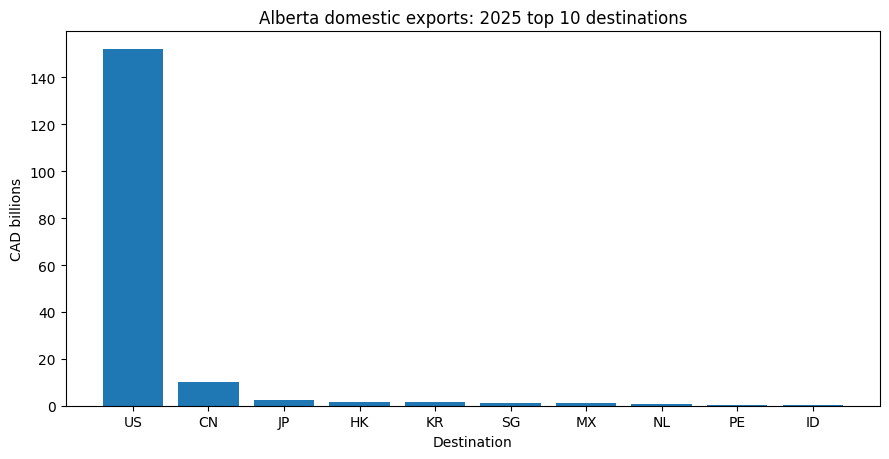

In [3]:
fig,ax=plt.subplots(figsize=(9,4.7))
ax.bar(actual['destination'],actual['CAD_billion'])
ax.set(title='Alberta domestic exports: 2025 top 10 destinations',ylabel='CAD billions',xlabel='Destination')
plt.tight_layout();fig.savefig(OUT/'q1_observed_top10.png',dpi=170);plt.show()

## B. Model holdout audit (seven-country training universe)

In [4]:
m=pd.read_csv(P/'model_comparison.csv')
display(m[['model','test_exporters','r2_value','wape','mae_usd_thousands']].round(4))
m.to_csv(OUT/'q1_model_comparison.csv',index=False)
print('Holdout performance is modest; do not infer high-confidence country-level forecast accuracy.')

,model,test_exporters,r2_value,wape,mae_usd_thousands
0,hist_gradient_boosting,MX;GB,0.0409,0.9460,42900.9814
1,extra_trees,MX;GB,0.0382,0.9400,42629.7445
2,random_forest,MX;GB,0.0426,0.9489,43033.4007
3,ridge_log,MX;GB,0.0505,0.9496,43061.6667
4,zero_naive,MX;GB,-0.0034,1.0000,45349.1712


Holdout performance is modest; do not infer high-confidence country-level forecast accuracy.


## C. 2025 scenario, explicitly NOT a validated ML forecast

In [5]:
scenario=pd.read_csv(P/'global_2025_conditional_baseline_top10_top5.csv',dtype={'hs4':str})
sc=(scenario.groupby(['country_iso2','country_name'],as_index=False)['destination_total_cad'].first().sort_values('destination_total_cad',ascending=False))
sc['CAD_billion']=sc['destination_total_cad']/1e9
display(sc[['country_iso2','country_name','CAD_billion']].round(3))
sc.to_csv(OUT/'q1_conditional_scenario_destinations_NOT_FORECAST.csv',index=False)

,country_iso2,country_name,CAD_billion
9,US,USA,120.170
0,CN,China,16.293
3,IN,India,5.228
5,JP,Japan,4.769
6,KR,Rep. of Korea,3.850
7,NL,Netherlands,2.636
1,DE,Germany,2.091
4,IT,Italy,1.822
2,GB,United Kingdom,1.576
8,SG,Singapore,1.563


## D. Interpretation
The observed 2025 table answers the descriptive question. The BACI-based seven-economy model is an exploratory signal; its holdout metrics must accompany any model claims. The global scenario is a *judgmental conditional allocation* and should not be presented as the model's validated 2025 predictions.

## E. References

Centre d’Études Prospectives et d’Informations Internationales. (2026). *BACI international trade database (HS 2022)* [Data set]. https://www.cepii.fr/CEPII/en/bdd_modele/bdd_modele_item.asp?id=37

Statistics Canada. (2026). *Canadian international merchandise trade: Domestic exports by province, destination, and commodity, 2025* [Data set]. https://www.statcan.gc.ca/

World Bank. (2026). *World development indicators* [Data set]. https://databank.worldbank.org/source/world-development-indicators

United States International Trade Commission. (2026). *Harmonized tariff schedule archive*. https://www.usitc.gov/harmonized_tariff_information/hts/archive/list